Filter primitives: shadows, noise, lighting and color matrices.

Run it as ``python filter_effects.py [OUTPUT_DIR]`` or open ``filter_effects.ipynb`` to see each step.

In [1]:
import sys
import tempfile
from pathlib import Path

import svgwriter as svg
from svgwriter.elements import filters as fe

Filters are defined once with `doc.define(...)` and referenced by shapes through `filter=`.
Primitives chain: turbulence noise, desaturated by a color matrix, makes a paper texture.

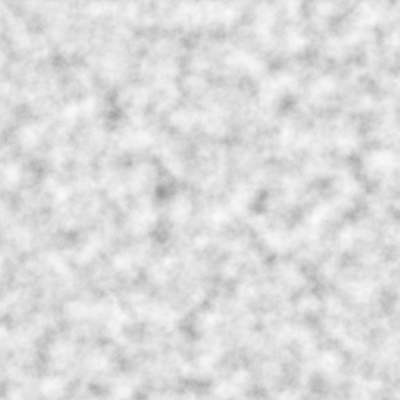

In [2]:
SIZE = 400
TILE = 160

doc = svg.Document(SIZE, SIZE)
noise = fe.FeTurbulence(0.04, 4, seed=7, type=fe.TurbulenceType.FRACTAL_NOISE)
paper = doc.define(svg.Filter(noise, fe.FeColorMatrix.saturate(0), x=0, y=0, width="100%", height="100%"))
doc.add(svg.Rect(0, 0, SIZE, SIZE, filter=paper))
doc

`svg.drop_shadow` is a ready-made filter for a soft shadow.

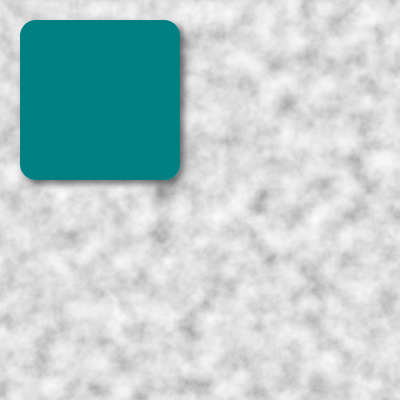

In [3]:
shadow = doc.define(svg.drop_shadow(4, 4, 3, "black", 0.5))
doc.add(svg.Rect(20, 20, TILE, TILE, rx=16, fill="teal", filter=shadow))
doc

Lighting: blur the alpha into a bump map, light it with a point light, clip the highlight to the
shape and add it back onto the source graphic.

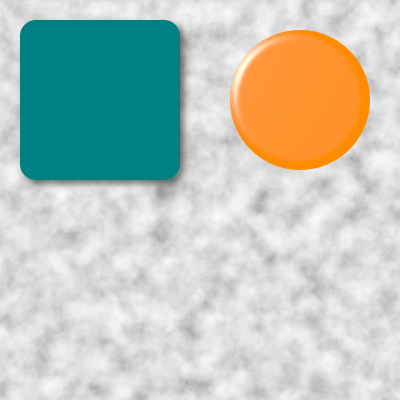

In [4]:
bump = fe.FeGaussianBlur(4, in_=fe.StandardInput.SOURCE_ALPHA)
light = fe.FeSpecularLighting(
    fe.FePointLight(-50, -100, 200),
    in_=bump,
    surface_scale=5,
    specular_constant=0.8,
    specular_exponent=20,
    lighting_color="white",
)
clipped = fe.FeComposite(fe.CompositeOperator.IN, in_=light, in2=fe.StandardInput.SOURCE_ALPHA)
shine = fe.FeComposite(fe.CompositeOperator.ARITHMETIC, in_=fe.StandardInput.SOURCE_GRAPHIC, in2=clipped, k1=0, k2=1, k3=1, k4=0)
embossed = doc.define(svg.Filter(bump, light, clipped, shine))
doc.add(svg.Circle(300, 100, 70, fill="darkorange", filter=embossed))
doc

A color matrix on text: `FeColorMatrix.grayscale()` removes the purple.

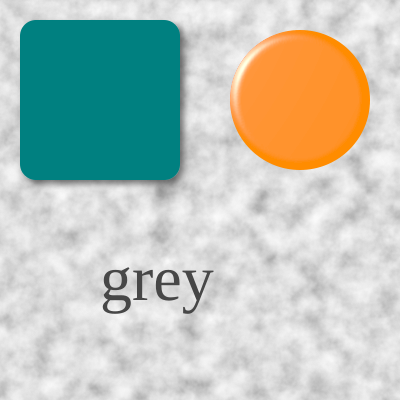

In [5]:
grey = doc.define(svg.Filter(fe.FeColorMatrix.grayscale()))
doc.add(svg.Text("grey", x=100, y=300, font_size=64, fill="purple", filter=grey))
doc

Save it with an XML doctype. Pass a folder as the first argument to choose where the file goes.

In [6]:
args = sys.argv[1:2]
out = Path(args[0]) if args and not args[0].startswith("-") else Path(tempfile.mkdtemp(prefix="svgwriter-"))
doc.save(out / "filter_effects.svg", doctype=True)
print("saved filter_effects.svg")

saved filter_effects.svg
